# 05 — Priority Matrix & Market Segmentation
### Kenya Clean Cooking Access Gap Analysis

This notebook produces the strategic output layer:
- **4-Quadrant Priority Matrix**: population vs. access gap
- **K-Means County Clustering**: market archetypes for intervention design
- **Affordability vs. Distribution gap analysis**: what type of barrier dominates per county?

This is the layer that turns a mapping exercise into a BI deliverable.

In [7]:
# %pip install scikit-learn nbformat
# %pip install --upgrade nbformat>=4.2.0
import pandas as pd
import nbformat
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from pathlib import Path

ROOT      = Path('..').resolve()
PROCESSED = ROOT / 'data' / 'processed'
CHARTS    = ROOT / 'outputs' / 'charts'
TABLES    = ROOT / 'outputs' / 'tables'
CHARTS.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PROCESSED / 'kenya_county_clean_cooking.csv')
print(f'Loaded: {len(df)} counties')
df.head()

Loaded: 47 counties


,county_name,clean_cooking_rate,female_headed_rate,urban_rate,wealth_index_mean,wealth_quintile_mode,sample_hh,fuel_code_1_pct,fuel_code_2_pct,fuel_code_3_pct,...,fuel_code_15_pct,fuel_code_16_pct,fuel_code_17_pct,fuel_code_95_pct,fuel_code_96_pct,population_2019,total_households_est,hh_without_clean_cooking,hh_gap_to_100pct,priority_score
0,Baringo,0.059078,0.357085,0.168598,-40890.012450,1.0,774.0,0.000000,0.080103,0.000000,...,0.000000,0.0,0.000000,0.024548,0.0,666763,170965,160865.0,160865.0,0.370669
1,Bomet,0.087477,0.309526,0.044721,-33429.810948,2.0,822.0,0.001217,0.138686,0.000000,...,0.000000,0.0,0.000000,0.036496,0.0,875689,224536,204894.0,204894.0,0.457872
2,Bungoma,0.117637,0.327396,0.126619,-15144.484834,2.0,854.0,0.000000,0.148712,0.000000,...,0.000000,0.0,0.015222,0.016393,0.0,1670570,428351,377961.0,377961.0,0.816705
3,Busia,0.089538,0.350505,0.143876,-19874.790963,2.0,834.0,0.002398,0.140288,0.000000,...,0.001199,0.0,0.000000,0.005995,0.0,893681,229149,208631.0,208631.0,0.465170
4,Elgeyo-Marakwet,0.078646,0.298102,0.048947,-30831.694605,1.0,749.0,0.001335,0.102804,0.001335,...,0.000000,0.0,0.000000,0.006676,0.0,454480,116533,107368.0,107368.0,0.242255


---
## 1. Four-Quadrant Priority Matrix

In [8]:
# Axes
# X: total households (market size)
# Y: access gap (1 - clean_cooking_rate) — how far from clean cooking
# Bubble size: absolute number of HH without clean cooking
# Color: urban rate (urban = supply-side opportunity, rural = distribution challenge)

df['access_gap'] = 1 - df['clean_cooking_rate']

# Medians for quadrant lines
x_median = df['total_households_est'].median()
y_median = df['access_gap'].median()

def quadrant_label(row):
    if row['total_households_est'] >= x_median and row['access_gap'] >= y_median:
        return 'HIGH PRIORITY\n(Large market, large gap)'
    elif row['total_households_est'] >= x_median and row['access_gap'] < y_median:
        return 'CONSOLIDATE\n(Large market, smaller gap)'
    elif row['total_households_est'] < x_median and row['access_gap'] >= y_median:
        return 'TARGETED INTERVENTION\n(Smaller market, large gap)'
    else:
        return 'MAINTENANCE\n(Smaller market, smaller gap)'

df['quadrant'] = df.apply(quadrant_label, axis=1)

fig = px.scatter(
    df,
    x='total_households_est',
    y='access_gap',
    size='hh_without_clean_cooking',
    color='urban_rate',
    text='county_name',
    hover_data={
        'county_name': True,
        'clean_cooking_rate': ':.1%',
        'hh_without_clean_cooking': ':,.0f',
        'urban_rate': ':.1%',
        'total_households_est': ':,.0f',
    },
    color_continuous_scale='RdYlGn',
    size_max=55,
    title='Kenya County Market Priority Matrix<br><sup>Bubble size = Households without clean cooking | Color = Urbanisation rate</sup>',
    labels={
        'total_households_est': 'Total Households (Market Size)',
        'access_gap': 'Access Gap (1 − Clean Cooking Rate)',
        'urban_rate': 'Urban Rate',
    },
    template='plotly_white',
)

# Quadrant lines
fig.add_vline(x=x_median, line_dash='dash', line_color='#aaa', line_width=1)
fig.add_hline(y=y_median, line_dash='dash', line_color='#aaa', line_width=1)

# Quadrant labels
annotations = [
    dict(x=df['total_households_est'].max()*0.95, y=df['access_gap'].max()*0.97,
         text='🔴 HIGH PRIORITY', showarrow=False, font=dict(size=11, color='#c0392b')),
    dict(x=df['total_households_est'].max()*0.95, y=y_median*0.3,
         text='🟡 CONSOLIDATE', showarrow=False, font=dict(size=11, color='#e67e22')),
    dict(x=x_median*0.1, y=df['access_gap'].max()*0.97,
         text='🟠 TARGETED', showarrow=False, font=dict(size=11, color='#d35400')),
    dict(x=x_median*0.1, y=y_median*0.3,
         text='🟢 MAINTENANCE', showarrow=False, font=dict(size=11, color='#27ae60')),
]
fig.update_layout(annotations=annotations, height=600)
fig.update_traces(textposition='top center', textfont_size=9)

fig.write_html(str(CHARTS / 'priority_matrix.html'))
print('Saved priority_matrix.html')
fig.show()

Saved priority_matrix.html


---
## 2. Affordability vs. Distribution Gap Analysis

In [9]:
# Counties with high wealth index but low clean cooking = DISTRIBUTION/BEHAVIORAL gap
# Counties with low wealth index and low clean cooking  = AFFORDABILITY gap

if 'wealth_index_mean' in df.columns and df['wealth_index_mean'].notna().sum() > 10:
    wealth_median = df['wealth_index_mean'].median()
    
    def gap_type(row):
        if row['wealth_index_mean'] >= wealth_median and row['clean_cooking_rate'] < 0.5:
            return 'Distribution/Behavioural Gap'
        elif row['wealth_index_mean'] < wealth_median and row['clean_cooking_rate'] < 0.5:
            return 'Affordability Gap'
        elif row['clean_cooking_rate'] >= 0.5:
            return 'Relatively High Access'
        else:
            return 'Mixed'

    df['gap_type'] = df.apply(gap_type, axis=1)

    fig2 = px.scatter(
        df,
        x='wealth_index_mean',
        y='clean_cooking_rate',
        color='gap_type',
        size='hh_without_clean_cooking',
        text='county_name',
        color_discrete_map={
            'Distribution/Behavioural Gap': '#e74c3c',
            'Affordability Gap': '#e67e22',
            'Relatively High Access': '#2ecc71',
            'Mixed': '#95a5a6',
        },
        title='Income vs. Clean Cooking Access — Diagnosing the Gap Type<br><sup>Bubble size = HH without clean cooking</sup>',
        labels={
            'wealth_index_mean': 'Mean Wealth Index (Facebook RWI)',
            'clean_cooking_rate': 'Clean Cooking Access Rate',
        },
        template='plotly_white',
        size_max=45,
    )
    fig2.add_hline(y=0.5, line_dash='dot', line_color='#888', annotation_text='50% access line')
    fig2.update_traces(textposition='top center', textfont_size=8)
    fig2.update_layout(height=580)
    fig2.write_html(str(CHARTS / 'affordability_vs_distribution_gap.html'))
    print('Saved affordability_vs_distribution_gap.html')
    fig2.show()
else:
    print('Wealth index data not yet available — add Facebook RWI in notebook 02 to enable this analysis.')

Saved affordability_vs_distribution_gap.html


---
## 3. K-Means County Clustering

In [10]:
# Features for clustering
cluster_features = [
    'clean_cooking_rate',
    'urban_rate',
    'access_gap',
    'total_households_est',
]

# Add wealth index if available
if 'wealth_index_mean' in df.columns:
    cluster_features.append('wealth_index_mean')

available_features = [f for f in cluster_features if f in df.columns and df[f].notna().all()]
X = df[available_features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4 clusters — maps to 4 market archetypes
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

# Label clusters by their profile
cluster_profiles = df.groupby('cluster')[available_features].mean()
print('Cluster profiles (means):')
print(cluster_profiles.round(3))

# Map cluster numbers to descriptive labels based on profiles
# (Adjust after inspecting cluster_profiles output)
CLUSTER_LABELS = {
    0: 'Urban Leaders (high access, high urbanisation)',
    1: 'Rural Frontier (large gap, low density)',
    2: 'Mid-tier Urban (moderate access, growing)',
    3: 'High-Deficit Hubs (large population, large gap)',
}
df['cluster_label'] = df['cluster'].map(CLUSTER_LABELS)

# Plot
fig3 = px.scatter(
    df,
    x='total_households_est',
    y='clean_cooking_rate',
    color='cluster_label',
    size='hh_without_clean_cooking',
    text='county_name',
    title='Kenya County Market Archetypes — K-Means Clustering<br><sup>4 clusters by access rate, urbanisation, and market size</sup>',
    labels={
        'total_households_est': 'Total Households',
        'clean_cooking_rate': 'Clean Cooking Access Rate',
    },
    template='plotly_white',
    size_max=45,
    color_discrete_sequence=px.colors.qualitative.Bold,
)
fig3.update_traces(textposition='top center', textfont_size=8)
fig3.update_layout(height=580)
fig3.write_html(str(CHARTS / 'county_clusters.html'))
print('Saved county_clusters.html')
fig3.show()

Cluster profiles (means):
         clean_cooking_rate  urban_rate  access_gap  total_households_est  \
cluster                                                                     
0                     0.370       0.518       0.630            262952.444   
1                     0.712       0.877       0.288            873693.500   
2                     0.042       0.282       0.958            156886.286   
3                     0.130       0.176       0.870            240821.172   

         wealth_index_mean  
cluster                     
0                43948.223  
1               110261.451  
2               -99053.108  
3               -14481.689  
Saved county_clusters.html


---
## 4. Export Final Summary Table

In [11]:
summary_cols = [
    'county_name', 'population_2019', 'total_households_est',
    'clean_cooking_rate', 'access_gap', 'hh_without_clean_cooking',
    'priority_score', 'quadrant', 'urban_rate', 'cluster_label',
]
available_summary = [c for c in summary_cols if c in df.columns]

df_summary = (
    df[available_summary]
    .sort_values('priority_score', ascending=False)
    .reset_index(drop=True)
)
df_summary.index += 1  # rank from 1
df_summary.index.name = 'rank'

out_path = TABLES / 'kenya_county_priority_summary.csv'
df_summary.to_csv(out_path)
print(f'Saved: {out_path}')
print(f'\nTop 10 Priority Counties:')
print(df_summary.head(10)[['county_name', 'clean_cooking_rate', 'hh_without_clean_cooking', 'priority_score', 'quadrant']].to_string())

Saved: C:\Users\eric.njiraini\Documents\My Projects at a Go\kenya-clean-cooking-gap\outputs\tables\kenya_county_priority_summary.csv

Top 10 Priority Counties:
     county_name  clean_cooking_rate  hh_without_clean_cooking  priority_score                                  quadrant
rank                                                                                                                    
1       Kakamega            0.135427                  414015.0        0.876575  HIGH PRIORITY\n(Large market, large gap)
2        Bungoma            0.117637                  377961.0        0.816705  HIGH PRIORITY\n(Large market, large gap)
3           Meru            0.133031                  343612.0        0.729530  HIGH PRIORITY\n(Large market, large gap)
4         Kilifi            0.140882                  320250.0        0.673772  CONSOLIDATE\n(Large market, smaller gap)
5       Homa Bay            0.090253                  264049.0        0.588269  HIGH PRIORITY\n(Large market, larg

---
## 5. Last Step: Export Images

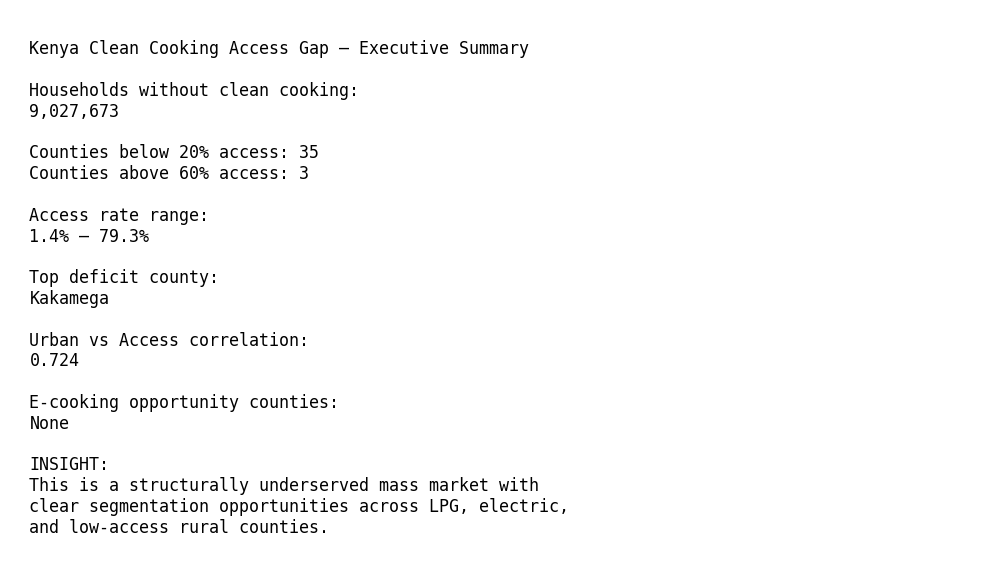

✅ Saved:
 - outputs/tables/eda_summary.csv
 - outputs/tables/eda_summary.md
 - outputs/charts/eda/eda_summary.png


In [12]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------
# OUTPUT PATHS
# ----------------------------
ROOT = Path('..').resolve()
OUT_TABLES = ROOT / 'outputs' / 'tables'
OUT_EDA = ROOT / 'outputs' / 'charts' / 'eda'

OUT_TABLES.mkdir(parents=True, exist_ok=True)
OUT_EDA.mkdir(parents=True, exist_ok=True)

# ----------------------------
# METRICS (FROM YOUR DF)
# ----------------------------
metrics = {
    "households_without_clean_cooking": int(df["hh_without_clean_cooking"].sum()),
    "counties_below_20pct": int((df["clean_cooking_rate"] < 0.20).sum()),
    "counties_above_60pct": int((df["clean_cooking_rate"] > 0.60).sum()),
    "min_access_rate": float(df["clean_cooking_rate"].min()),
    "max_access_rate": float(df["clean_cooking_rate"].max()),
    "top_deficit_county": df.nlargest(1, "hh_without_clean_cooking")["county_name"].values[0],
    "urban_access_corr": float(df[["urban_rate", "clean_cooking_rate"]].corr().iloc[0,1]) if "urban_rate" in df.columns else None,
    "h2_e_cooking_opportunity_count": int((df["cooking_archetype"] == "E-cooking opportunity").sum()) if "cooking_archetype" in df.columns else None,
}

# ----------------------------
# 1. SAVE CSV SUMMARY
# ----------------------------
df_summary = pd.DataFrame(metrics.items(), columns=["metric", "value"])
df_summary.to_csv(OUT_TABLES / "eda_summary.csv", index=False)

# ----------------------------
# 2. SAVE MARKDOWN SUMMARY
# ----------------------------
md_text = f"""
## EDA Summary — Kenya Clean Cooking Access Gap

### Key Metrics
- Households without clean cooking: **{metrics['households_without_clean_cooking']:,}**
- Counties below 20% access: **{metrics['counties_below_20pct']}**
- Counties above 60% access: **{metrics['counties_above_60pct']}**
- Access rate range: **{metrics['min_access_rate']:.1%} – {metrics['max_access_rate']:.1%}**
- Highest deficit county: **{metrics['top_deficit_county']}**

### Strategic Insights
- Urban vs Access correlation: **{metrics.get('urban_access_corr', 'N/A'):.3f}**
- E-cooking opportunity counties: **{metrics.get('h2_e_cooking_opportunity_count', 'N/A')}**

### Interpretation
- Large structural gap (~9M households) indicates a **mass market opportunity**
- Weak/negative urban correlation confirms **non-linear adoption drivers**
- LPG vs electricity segmentation reveals **two distinct intervention pathways**
"""

with open(OUT_TABLES / "eda_summary.md", "w") as f:
    f.write(md_text)

# ----------------------------
# 3. EXECUTIVE SUMMARY IMAGE
# ----------------------------
fig, ax = plt.subplots(figsize=(10, 6))
ax.axis("off")

title = "Kenya Clean Cooking Access Gap — Executive Summary"

text = f"""
{title}

Households without clean cooking:
{metrics['households_without_clean_cooking']:,}

Counties below 20% access: {metrics['counties_below_20pct']}
Counties above 60% access: {metrics['counties_above_60pct']}

Access rate range:
{metrics['min_access_rate']:.1%} – {metrics['max_access_rate']:.1%}

Top deficit county:
{metrics['top_deficit_county']}

Urban vs Access correlation:
{metrics.get('urban_access_corr', 'N/A'):.3f}

E-cooking opportunity counties:
{metrics.get('h2_e_cooking_opportunity_count', 'N/A')}

INSIGHT:
This is a structurally underserved mass market with
clear segmentation opportunities across LPG, electric,
and low-access rural counties.
"""

ax.text(0.02, 0.98, text, va="top", ha="left", fontsize=12, family="monospace")

plt.tight_layout()
plt.savefig(OUT_EDA / "eda_summary.png", dpi=200, bbox_inches="tight")
plt.show()

print("✅ Saved:")
print(" - outputs/tables/eda_summary.csv")
print(" - outputs/tables/eda_summary.md")
print(" - outputs/charts/eda/eda_summary.png")